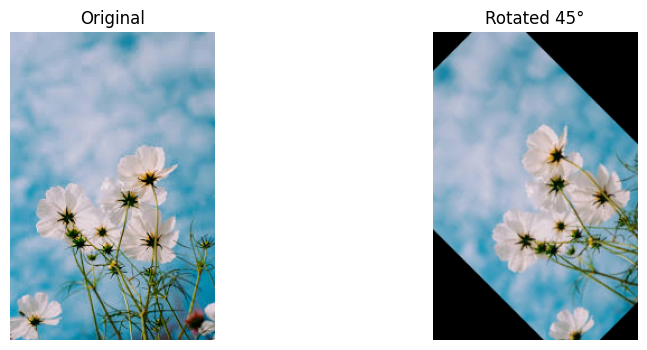

In [ ]:
import matplotlib.pyplot as plt
import cv2

# Upload an image in Colab, then set its path:
image = cv2.imread("/content/download88.png")

height, width = image.shape[:2]
center = (width / 2, height / 2)

# Positive 45 degrees; scale = 1 keeps the nominal size
M = cv2.getRotationMatrix2D(center, 45, 1.0)
M = np.vstack([M, [0, 0, 1]])
rotated = cv2.warpPerspective(image, M, (width, height))

# OpenCV loads BGR; convert to RGB for Matplotlib
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original"); plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(rotated, cv2.COLOR_BGR2RGB))
plt.title("Rotated 45°"); plt.axis("off")
plt.show()

Area = 12961 px², equivalent radius = 64.2 px, center = (682.4, 556.0)


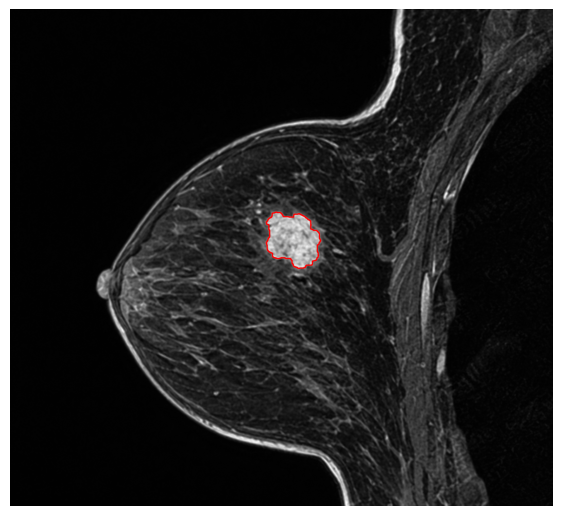

In [ ]:
import cv2, numpy as np
from scipy import ndimage as ndi
import matplotlib.pyplot as plt

img = cv2.imread("/content/Breast_Cancer_MRI.png", cv2.IMREAD_GRAYSCALE)

# 1. Thresholding with a manual T
T = 150
b = (img >= T).astype(np.uint8)

# 2. Segmentation: label connected components
n, labels, stats, centroids = cv2.connectedComponentsWithStats(b, connectivity=8)

# 3. Pick the largest foreground component automatically
if n > 1:
    k = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    tumor = (labels == k).astype(np.uint8)
else:
    tumor = np.zeros_like(b)

# 4. Clean up: close small gaps and fill holes inside the tumor
tumor = cv2.morphologyEx(tumor, cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8))
tumor = ndi.binary_fill_holes(tumor).astype(np.uint8)

# 5. Geometric properties
A = int(tumor.sum())                           # area = sum of b_ij (slide 20)
ys, xs = np.nonzero(tumor)
xbar, ybar = xs.mean(), ys.mean()              # center of area
r_eq = np.sqrt(A / np.pi)                      # equivalent radius
print(f"Area = {A} px², equivalent radius = {r_eq:.1f} px, center = ({xbar:.1f}, {ybar:.1f})")

# 6. Check it visually
cnt, _ = cv2.findContours(tumor, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
out = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
cv2.drawContours(out, cnt, -1, (0, 0, 255), 2)
plt.figure(figsize=(7, 7));
plt.imshow(out[..., ::-1]);
plt.axis("off");
plt.show()